# Incendios en el Perú, octubre de 2026 · 2. De focos de calor a incendios, y a quién alcanzan

Del dato crudo de focos a una tabla de incendios, y cuántas personas viven cerca de cada uno, en *todo* el país:

| Etapa | Qué hacemos |
|---|---|
| Focos | Unir 3 satélites, quitar baja confianza, volcanes y fuentes fijas |
| Incendios | Focos a ≤ 1 km y ≤ 48 h entre sí = un incendio |
| Población cercana | Personas a 5 km de cada incendio (WorldPop, raster → tabla con `zonal_stats`) |

> Un foco de calor no es un incendio: es un píxel de 375 m donde el satélite midió calor
> anómalo. Puede ser una quema agrícola, un incendio forestal o una chimenea.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rasterstats import zonal_stats

from comun import RAW, PROC, FIG, CRS_METRICO, VOLCANES, leer_distritos, leer_focos, agrupar_incendios

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## Focos y limpieza

In [2]:
focos = leer_focos()
print(f"focos VIIRS en el Perú: {len(focos):,}  ({focos.acq_date.min()} a {focos.acq_date.max()}, hora UTC)")
print(focos.sat.value_counts().to_string())
print(focos.confidence.value_counts().to_string())

focos VIIRS en el Perú: 9,949  (2026-10-14 a 2026-10-21, hora UTC)
sat
snpp       3552
noaa-21    3434
noaa-20    2963
confidence
nominal    8010
low        1336
high        603


Tres filtros, cada uno con su razón:

1. **Confianza baja** (`low`): FIRMS la marca así cuando la señal es débil o hay reflejo solar.
2. **Volcanes**: Sabancaya, Ubinas y Misti emiten calor todo el año. Se quitan los focos a < 5 km.
3. **Fuentes fijas**: un incendio se mueve; una fundición o un mechero no. Un píxel de 375 m
   con calor en **5 o más de los 8 días** se trata como fuente fija.

In [3]:
n0 = len(focos)
focos = focos[focos.confidence != "low"]
n_baja = n0 - len(focos)

m = focos.to_crs(CRS_METRICO)
volc = gpd.GeoSeries(gpd.points_from_xy(*zip(*VOLCANES.values())), crs=4326).to_crs(CRS_METRICO)
cerca_volcan = m.geometry.apply(lambda p: volc.distance(p).min() < 5000)

focos["pixel"] = ((m.geometry.x // 375).astype(int).astype(str) + "_"
                  + (m.geometry.y // 375).astype(int).astype(str))
dias_por_pixel = focos.groupby("pixel").acq_date.nunique()
fijo = focos.pixel.map(dias_por_pixel) >= 5

limpieza = pd.Series({"confianza baja": n_baja, "volcán (< 5 km)": int(cerca_volcan.sum()),
                      "fuente fija (≥ 5 días)": int((fijo & ~cerca_volcan).sum())})
focos = focos[~cerca_volcan & ~fijo].copy()
print(limpieza.to_string())
print(f"focos limpios: {len(focos):,} de {n0:,}")

confianza baja            1336
volcán (< 5 km)              0
fuente fija (≥ 5 días)      26
focos limpios: 8,587 de 9,949


## Incendios: ≤ 1 km y ≤ 48 h

Construimos un grafo: cada foco es un nodo y dos focos se conectan si están a 1 km o menos
**y** a 48 horas o menos. Cada componente conectada es un incendio.

La **huella** es el área de los píxeles de 375 m con fuego (14,06 ha cada uno). No es el área
quemada oficial: eso se mide con Sentinel-2 en el notebook 3.

In [4]:
focos["incendio"] = agrupar_incendios(focos, km=1, horas=48)
t_corte = focos.t.max()

incendios = focos.groupby("incendio").agg(
    focos=("t", "size"), pixeles=("pixel", "nunique"),
    inicio=("t", "min"), ultimo=("t", "max"), frp_mw=("frp", "sum"),
    distrito=("NOMBDIST", lambda s: s.value_counts().index[0]),
    provincia=("NOMBPROV", lambda s: s.value_counts().index[0]),
    departamento=("NOMBDEP", lambda s: s.value_counts().index[0]),
    ubigeo=("IDDIST", lambda s: s.value_counts().index[0]),
)
incendios["huella_ha"] = incendios.pixeles * 375 * 375 / 1e4
incendios["activo_24h"] = incendios.ultimo >= t_corte - pd.Timedelta("24h")
print(f"{len(incendios):,} incendios · {(incendios.huella_ha > 100).sum()} con huella > 100 ha · "
      f"corte {t_corte:%d/%m %H:%M} UTC")

2,587 incendios · 107 con huella > 100 ha · corte 21/10 19:19 UTC


Nos quedamos con los incendios con huella **> 100 ha** : por debajo
de eso, buena parte son quemas agrícolas de uno o dos píxeles.

In [5]:
grandes = incendios[incendios.huella_ha > 100].copy()

# Zona de 5 km alrededor de los focos de cada incendio
zona5 = (focos[focos.incendio.isin(grandes.index)].to_crs(CRS_METRICO)
         .groupby("incendio").geometry.apply(lambda s: s.buffer(5000).union_all()))
zona5 = gpd.GeoSeries(zona5, crs=CRS_METRICO).to_crs(4326).loc[grandes.index]

## ¿A quién afecta? Personas a 5 km

La operación central de la clase: **raster → tabla**. `zonal_stats` suma los píxeles de
WorldPop (personas por km²) dentro de cada zona de 5 km.

- `nodata`: WorldPop usa `-99999`; lo leemos del archivo en lugar de suponerlo.
- `all_touched=False`: con zonas de 5 km de radio (≥ 78 km²) el borde pesa poco y evitamos
  contar dos veces píxeles compartidos.

In [6]:
import rasterio
WORLDPOP = RAW / "worldpop_per_2020_1km.tif"
with rasterio.open(WORLDPOP) as src:
    print(f"WorldPop: {src.width}×{src.height} px, {src.res[0]*111:.2f} km, nodata={src.nodata}, CRS {src.crs}")
    nodata_wp = src.nodata

grandes["personas_5km"] = [z["sum"] or 0 for z in
                           zonal_stats(list(zona5), WORLDPOP, stats=["sum"], nodata=nodata_wp)]
print(f"personas a 5 km de algún incendio > 100 ha: {grandes.personas_5km.sum():,.0f} (con superposición entre zonas)")
union = gpd.GeoSeries([zona5.union_all()], crs=4326)
sin_doble = zonal_stats(list(union), WORLDPOP, stats=["sum"], nodata=nodata_wp)[0]["sum"]
print(f"personas sin contar dos veces (unión de zonas): {sin_doble:,.0f}")

WorldPop: 1522×2199 px, 0.92 km, nodata=-99999.0, CRS EPSG:4326


personas a 5 km de algún incendio > 100 ha: 369,138 (con superposición entre zonas)
personas sin contar dos veces (unión de zonas): 337,069


In [7]:
cols = ["distrito", "provincia", "departamento", "focos", "huella_ha", "frp_mw", "personas_5km", "activo_24h"]
print("Los 12 incendios más grandes de la semana")
print(grandes.sort_values("huella_ha", ascending=False)[cols].head(12).round(0).to_string())

Los 12 incendios más grandes de la semana
                   distrito         provincia departamento  focos  huella_ha  frp_mw  personas_5km  activo_24h
incendio                                                                                                      
5                 RIO TAMBO            SATIPO        JUNIN    279     1927.0  2157.0        1380.0       False
10                CURAHUASI           ABANCAY     APURIMAC    201     1448.0  2408.0        1767.0       False
458                 CHICHAS        CONDESUYOS     AREQUIPA    178     1378.0  1637.0         228.0       False
94                 MANANTAY  CORONEL PORTILLO      UCAYALI    116      900.0  1720.0       21289.0       False
12               HUANOQUITE            PARURO        CUSCO     80      647.0  1313.0        1681.0       False
174                TAHUANIA           ATALAYA      UCAYALI    108      633.0  4840.0         178.0       False
203                    TAPO             TARMA        JUNIN     61     

In [8]:
print("Los 12 incendios con más personas a 5 km")
print(grandes.sort_values("personas_5km", ascending=False)[cols].head(12).round(0).to_string())

Los 12 incendios con más personas a 5 km
             distrito         provincia departamento  focos  huella_ha  frp_mw  personas_5km  activo_24h
incendio                                                                                                
461           ABANCAY           ABANCAY     APURIMAC     26      211.0   508.0       51429.0       False
100       YARINACOCHA  CORONEL PORTILLO      UCAYALI     32      267.0   423.0       29445.0       False
95           MANANTAY  CORONEL PORTILLO      UCAYALI     11      127.0   190.0       25377.0       False
94           MANANTAY  CORONEL PORTILLO      UCAYALI    116      900.0  1720.0       21289.0       False
429           HUANUCO           HUANUCO      HUANUCO     17      127.0   209.0       17051.0       False
937            YUNGAY            YUNGAY       ANCASH     11      112.0   100.0       15913.0       False
98        YARINACOCHA  CORONEL PORTILLO      UCAYALI     32      267.0   581.0       13594.0       False
150           

Las dos tablas cuentan historias distintas, como `mean` y `sum` en la clase: los incendios
**más grandes** están en la selva central y el sur andino, lejos de la gente. Los que tienen
**más personas cerca** son incendios medianos en el borde de ciudades (Abancay; Pucallpa con Yarinacocha y Manantay).
Para la antropología importan los dos: el tamaño del fuego no dice a cuánta gente toca.

### Tabla por distrito

Un distrito puede tener varios incendios. Sumamos huella y focos; para las personas usamos la
unión de las zonas del distrito, para no contar dos veces.

In [9]:
grandes["zona5"] = zona5
por_distrito = (grandes.groupby(["ubigeo", "distrito", "provincia", "departamento"])
                .agg(incendios=("focos", "size"), focos=("focos", "sum"),
                     huella_ha=("huella_ha", "sum"), zona=("zona5", lambda s: gpd.GeoSeries(s).union_all()))
                .reset_index())
por_distrito["personas_5km"] = [z["sum"] or 0 for z in zonal_stats(
    list(por_distrito.zona), WORLDPOP, stats=["sum"], nodata=nodata_wp)]
por_distrito = por_distrito.drop(columns="zona").sort_values("huella_ha", ascending=False)
print(f"{len(por_distrito)} distritos con al menos un incendio > 100 ha")
print(por_distrito.head(15).round(0).to_string(index=False))

77 distritos con al menos un incendio > 100 ha
ubigeo          distrito        provincia departamento  incendios  focos  huella_ha  personas_5km
120608         RIO TAMBO           SATIPO        JUNIN          3    331     2306.0        1773.0
030104         CURAHUASI          ABANCAY     APURIMAC          4    278     2081.0        3822.0
250106     NUEVA REQUENA CORONEL PORTILLO      UCAYALI          8    240     1702.0        1857.0
040604           CHICHAS       CONDESUYOS     AREQUIPA          1    178     1378.0         228.0
250107          MANANTAY CORONEL PORTILLO      UCAYALI          4    159     1252.0       34502.0
250203          TAHUANIA          ATALAYA      UCAYALI          3    154      970.0         514.0
250105       YARINACOCHA CORONEL PORTILLO      UCAYALI          3     82      731.0       40765.0
180101          MOQUEGUA   MARISCAL NIETO     MOQUEGUA          4     57      703.0        2377.0
081005        HUANOQUITE           PARURO        CUSCO          1     8

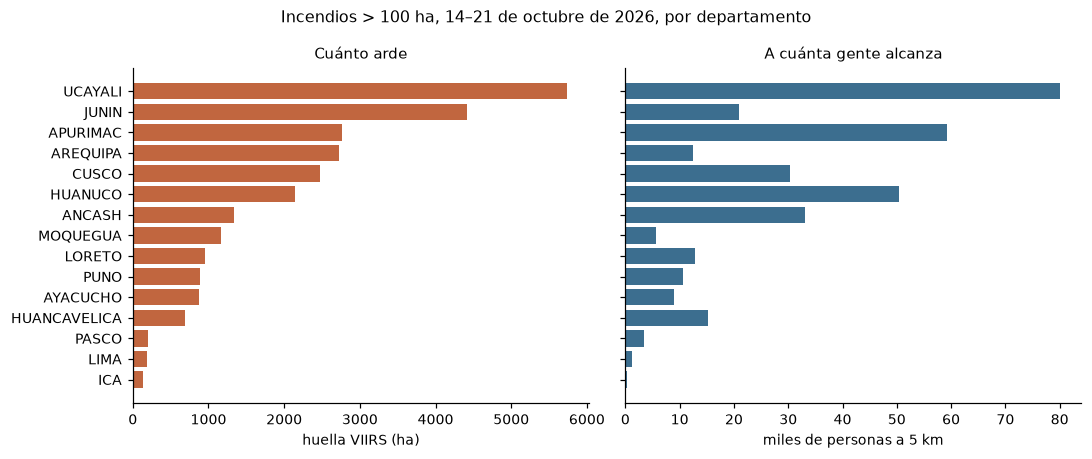

In [10]:
resumen_dep = (por_distrito.groupby("departamento")
               .agg(distritos=("ubigeo", "size"), huella_ha=("huella_ha", "sum"), personas_5km=("personas_5km", "sum"))
               .sort_values("huella_ha", ascending=False))
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
orden = resumen_dep.index[::-1]
izq.barh(orden, resumen_dep.loc[orden, "huella_ha"], color="#c1663f")
izq.set_xlabel("huella VIIRS (ha)"); izq.set_title("Cuánto arde", fontsize=9.5)
der.barh(orden, resumen_dep.loc[orden, "personas_5km"] / 1000, color="#3c6e8f")
der.set_xlabel("miles de personas a 5 km"); der.set_title("A cuánta gente alcanza", fontsize=9.5)
fig.suptitle("Incendios > 100 ha, 14–21 de octubre de 2026, por departamento", fontsize=10.5)
plt.tight_layout(); fig.savefig(FIG / "02_departamentos.png", dpi=150); plt.show()

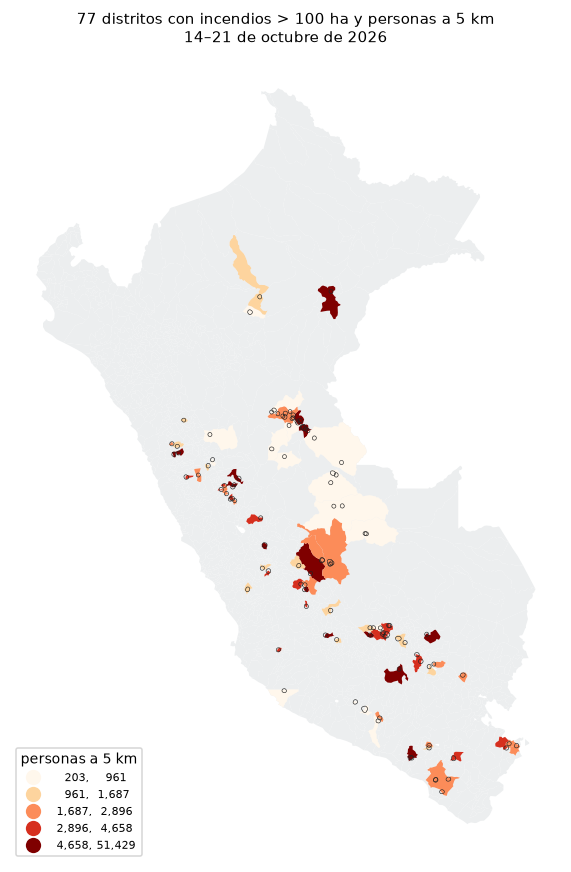

In [11]:
distritos = leer_distritos()
pob_dist = distritos.merge(por_distrito[["ubigeo", "personas_5km"]], left_on="IDDIST", right_on="ubigeo", how="left")
fig, ax = plt.subplots(figsize=(6.5, 8))
pob_dist.plot(ax=ax, color="#eceeef", linewidth=0)
pob_dist.dropna(subset=["personas_5km"]).plot(ax=ax, column="personas_5km", cmap="OrRd", scheme="quantiles", k=5,
                                              legend=True, linewidth=0,
                                              legend_kwds={"title": "personas a 5 km", "fontsize": 7, "loc": "lower left", "fmt": "{:,.0f}"})
gpd.GeoSeries(zona5, crs=4326).boundary.plot(ax=ax, color="#222", linewidth=0.4)
ax.set_title(f"{len(por_distrito)} distritos con incendios > 100 ha y personas a 5 km\n14–21 de octubre de 2026", fontsize=10)
ax.axis("off"); plt.tight_layout(); fig.savefig(FIG / "02_mapa_personas_5km.png", dpi=150); plt.show()

## Guardar para los siguientes notebooks

In [12]:
focos.drop(columns=["t"]).assign(t=focos.t.astype(str)).to_file(PROC / "focos_limpios.gpkg", driver="GPKG")
gpd.GeoDataFrame(grandes.drop(columns="zona5"), geometry=zona5, crs=4326).assign(
    inicio=lambda d: d.inicio.astype(str), ultimo=lambda d: d.ultimo.astype(str)
).to_file(PROC / "incendios_100ha_zona5km.gpkg", driver="GPKG")
por_distrito.to_csv(PROC / "distritos_personas_5km.csv", index=False)
limpieza.to_csv(PROC / "limpieza_focos.csv", header=["focos_quitados"])
print("guardado en", PROC)

guardado en /Users/greicyrc/Documents/GitHub/grey_diplomado/tarea_raster/datos/procesados
